# Random Forest — дослідження методу машинного навчання
**Практична частина: класифікація за допомогою `RandomForestClassifier` (scikit-learn)**

**Мета роботи:** на невеликому синтетичному наборі даних показати, як працює Random Forest, як гіперпараметри
(`n_estimators`, `max_depth` та ін.) впливають на якість класифікації, і порівняти метод з одним деревом рішень
та градієнтним бустингом.

**Сценарій.** Уявімо контроль якості на виробництві: за двома показниками (відхилення температури та рівня вібрації
від норми) потрібно передбачити, чи виріб **придатний** (клас 0) чи **бракований** (клас 1).
Дані **синтетичні** (генеруються `make_classification`), тому назви ознак — ілюстративні, а одиниці — умовні.

**План:** 1) середовище → 2) дані → 3) розбиття → 4) навчання → 5) метрики → 6) гіперпараметри →
7) візуалізація → 8) порівняння моделей → 9) висновки.

> Блокнот запускається зверху вниз без зовнішніх файлів. Усі числа нижче отримані реальним запуском коду.

## 1. Середовище та бібліотеки
Потрібні: Python 3.9+, NumPy, pandas, Matplotlib, scikit-learn; seaborn — лише для теплової карти матриці помилок.

Встановлення (виконайте один раз у терміналі або в окремій комірці):
```bash
pip install numpy pandas matplotlib scikit-learn seaborn jupyter
```

In [17]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import make_classification
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     StratifiedKFold, RepeatedStratifiedKFold)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42                      # єдине зерно для відтворюваності
COLORS = {0: "#2E7D4F", 1: "#E08A1E"}  # колір кожного класу (однаковий на всіх графіках)
CLASS_NAMES = ["Придатний (0)", "Бракований (1)"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

print("Python-бібліотеки:")
print("  numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python-бібліотеки:
  numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1


## 2. Генерація датасету
`make_classification` створює штучну задачу бінарної класифікації:
300 об'єктів, 2 інформативні ознаки (щоб побудувати двовимірні графіки), по 2 «кластери» на клас,
5 % випадково «перевернутих» міток (`flip_y=0.05`) та дисбаланс класів 60/40.
Шум і перетин класів зроблені навмисно, щоб задача не була тривіальною і різниця між моделями була помітною.

In [18]:
X_raw, y_raw = make_classification(
    n_samples=300,            # кількість об'єктів
    n_features=2,             # усього ознак
    n_informative=2,          # усі ознаки інформативні
    n_redundant=0,
    n_clusters_per_class=2,   # кожен клас складається з двох «хмар» -> нелінійна межа
    weights=[0.6, 0.4],       # приблизно 60 % придатних і 40 % бракованих
    class_sep=1.0,
    flip_y=0.05,              # 5 % шуму в мітках
    random_state=RANDOM_STATE,
)

feature_names = ["Температура", "Вібрація"]      # ілюстративні назви (умовні одиниці)
X = pd.DataFrame(X_raw, columns=feature_names)
y = pd.Series(y_raw, name="Брак")                # 0 = придатний, 1 = бракований

print("Розмір ознак:", X.shape, "| розмір міток:", y.shape)
print("Розподіл класів (кількість):", y.value_counts().sort_index().to_dict())
print("Розподіл класів (частка):  ", y.value_counts(normalize=True).sort_index().round(3).to_dict())
X.assign(Брак=y).describe().round(2)

Розмір ознак: (300, 2) | розмір міток: (300,)
Розподіл класів (кількість): {0: 181, 1: 119}
Розподіл класів (частка):   {0: 0.603, 1: 0.397}


,Температура,Вібрація,Брак
count,300.00,300.00,300.00
mean,0.05,-0.21,0.40
std,1.18,1.17,0.49
min,-2.71,-2.67,0.00
25%,-0.92,-1.14,0.00
50%,-0.02,-0.40,0.00
75%,1.07,0.88,1.00
max,2.47,2.66,1.00


### Графік 1. Розподіл об'єктів за двома ознаками

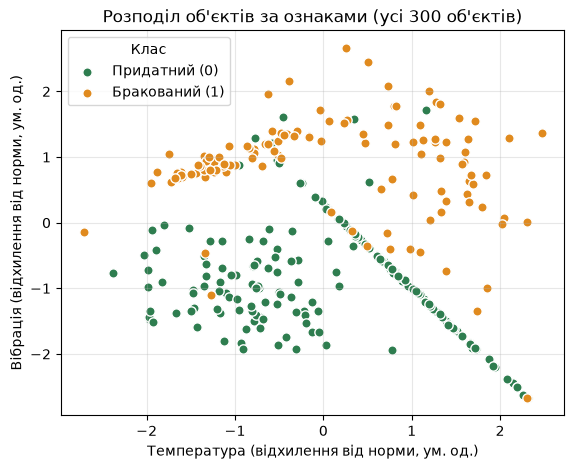

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for cls in (0, 1):
    mask = (y == cls)
    ax.scatter(X.loc[mask, "Температура"], X.loc[mask, "Вібрація"], c=COLORS[cls],
               edgecolor="white", s=45, label=CLASS_NAMES[cls])
ax.set_title("Розподіл об'єктів за ознаками (усі 300 об'єктів)")
ax.set_xlabel("Температура (відхилення від норми, ум. од.)")
ax.set_ylabel("Вібрація (відхилення від норми, ум. од.)")
ax.legend(title="Клас")
plt.show()

## 3. Розбиття на навчальну та тестову вибірки
75 % даних — навчання, 25 % — тест. `stratify=y` зберігає однакову частку бракованих у обох частинах.
**Тестова вибірка не використовується для підбору гіперпараметрів**: вибір налаштувань робимо крос-валідацією
лише на навчальній частині (розділ 6), а тест використовуємо для фінальної оцінки.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print("Навчальна вибірка:", X_train.shape, "| частка браку:", round(y_train.mean(), 3))
print("Тестова вибірка:  ", X_test.shape,  "| частка браку:", round(y_test.mean(), 3))

Навчальна вибірка: (225, 2) | частка браку: 0.396
Тестова вибірка:   (75, 2) | частка браку: 0.4


## 4. Навчання Random Forest
Основні параметри `RandomForestClassifier`, які ми задаємо явно:

| Параметр | Значення | Навіщо |
|---|---|---|
| `n_estimators=100` | 100 дерев | кількість дерев у лісі |
| `random_state=42` | 42 | відтворюваність (bootstrap і вибір ознак — випадкові) |
| `max_depth` | `None` (за замовч.) | дерева ростуть, доки листки не стануть «чистими» або малими |
| `max_features` | `"sqrt"` (за замовч.) | при розбитті розглядається випадкова підмножина ознак |
| `criterion` | `"gini"` (за замовч.) | критерій якості розбиття |
| `bootstrap` | `True` (за замовч.) | кожне дерево вчиться на bootstrap-вибірці |

Нижче — навчання та отримання передбачень: `predict` повертає клас, `predict_proba` — ймовірність класу.

> **Важливо про реалізацію.** У класичному описі Бреймана клас визначається більшістю голосів дерев. У scikit-learn кожне дерево повертає ймовірності класів (частки у листку), ліс їх **усереднює**, а `predict` обирає клас з найбільшою середньою ймовірністю («м'яке» голосування). Зазвичай результат близький до голосування більшістю, але не завжди ідентичний.

In [21]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)                 # підсумковий клас (голосування дерев)
y_proba = rf.predict_proba(X_test)[:, 1]    # оцінка ймовірності класу «Бракований»

print("Перші 8 передбачень :", y_pred[:8])
print("Перші 8 справжніх   :", y_test.values[:8])
print("Перші 8 ймовірностей:", y_proba[:8].round(2))

Перші 8 передбачень : [0 0 0 0 0 0 1 0]
Перші 8 справжніх   : [0 0 0 0 0 1 0 0]
Перші 8 ймовірностей: [0.01 0.22 0.29 0.08 0.   0.07 0.8  0.  ]


## 5. Оцінка якості
Позитивний клас — **«Бракований» (1)**.
- **Accuracy** — частка правильних відповідей; може вводити в оману при дисбалансі класів.
- **Precision** — із усіх виробів, названих бракованими, скільки справді бракованих.
- **Recall** — із усіх справжніх бракованих виробів, скільки модель знайшла.
- **F1-score** — гармонійне середнє precision і recall.
- **ROC-AUC** — якість ранжування за ймовірністю (не залежить від порога 0,5).
- **Матриця помилок** — кількість TP, TN, FP, FN.

In [22]:
def evaluate(model, X_te, y_te):
    """Повертає основні метрики класифікації на заданій вибірці."""
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall":    recall_score(y_te, pred),
        "F1":        f1_score(y_te, pred),
        "ROC-AUC":   roc_auc_score(y_te, proba),
    }

metrics_rf = pd.DataFrame([evaluate(rf, X_test, y_test)], index=["RandomForest (n=100)"]).round(3)
metrics_rf

,Accuracy,Precision,Recall,F1,ROC-AUC
RandomForest (n=100),0.933,0.931,0.9,0.915,0.952


### Графік 2. Матриця помилок (тестова вибірка)

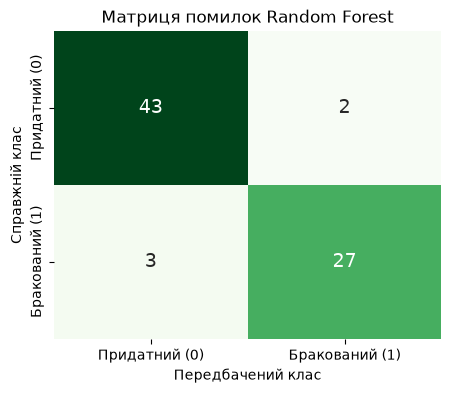

TN=43 (придатні, визначені вірно), FP=2 (хибна тривога), FN=3 (пропущений брак), TP=27


In [23]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 14})
ax.set_title("Матриця помилок Random Forest")
ax.set_xlabel("Передбачений клас")
ax.set_ylabel("Справжній клас")
ax.grid(False)
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} (придатні, визначені вірно), FP={fp} (хибна тривога), FN={fn} (пропущений брак), TP={tp}")

## 6. Експерименти з гіперпараметрами
Перевіряємо сітку **`n_estimators` ∈ {10, 50, 100, 300}** × **`max_depth` ∈ {2, 5, None}**.
Для кожної конфігурації рахуємо:
- метрики на **одній і тій самій тестовій вибірці** — *лише щоб показати вплив налаштувань*;
- `CV_F1` — середній F1 за 5-блокової стратифікованої крос-валідації **на навчальній вибірці**.
  Саме за `CV_F1` (а не за тестом) обираємо найкращу конфігурацію, щоб не підлаштовуватися під тест.

Зверніть увагу: тест містить лише 75 об'єктів, тому один об'єкт змінює accuracy приблизно на 1,3 п.п.
Малі різниці між конфігураціями можуть бути просто шумом.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_config(**params):
    """Навчає RF із заданими параметрами; повертає метрики (тест), CV на train і час навчання."""
    model = RandomForestClassifier(random_state=RANDOM_STATE, **params)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    m = evaluate(model, X_test, y_test)
    cv_f1 = cross_val_score(RandomForestClassifier(random_state=RANDOM_STATE, **params),
                            X_train, y_train, cv=cv, scoring="f1")
    return {"Train_Acc": model.score(X_train, y_train), "Test_Acc": m["Accuracy"],
            "Precision": m["Precision"], "Recall": m["Recall"], "F1": m["F1"],
            "ROC-AUC": m["ROC-AUC"], "CV_F1": cv_f1.mean(), "Час_навч_с": fit_time}

rows = []
for depth in [2, 5, None]:
    for n in [10, 50, 100, 300]:
        rows.append({"max_depth": "None" if depth is None else depth, "n_estimators": n,
                     **run_config(n_estimators=n, max_depth=depth)})

grid = pd.DataFrame(rows)
grid.round(3)

,max_depth,n_estimators,Train_Acc,Test_Acc,Precision,Recall,F1,ROC-AUC,CV_F1,Час_навч_с
0,2,10,0.911,0.853,0.788,0.867,0.825,0.923,0.872,0.012
1,2,50,0.911,0.853,0.788,0.867,0.825,0.946,0.877,0.048
2,2,100,0.911,0.853,0.788,0.867,0.825,0.950,0.877,0.089
3,2,300,0.911,0.853,0.788,0.867,0.825,0.948,0.877,0.264
4,5,10,0.947,0.933,0.931,0.900,0.915,0.952,0.859,0.011
5,5,50,0.964,0.933,0.931,0.900,0.915,0.940,0.882,0.045
6,5,100,0.964,0.907,0.871,0.900,0.885,0.956,0.888,0.087
7,5,300,0.956,0.907,0.871,0.900,0.885,0.948,0.882,0.280
8,None,10,0.987,0.907,0.871,0.900,0.885,0.942,0.859,0.011
9,None,50,1.000,0.933,0.931,0.900,0.915,0.945,0.869,0.048


### Графік 3. Вплив `n_estimators` і `max_depth` на якість

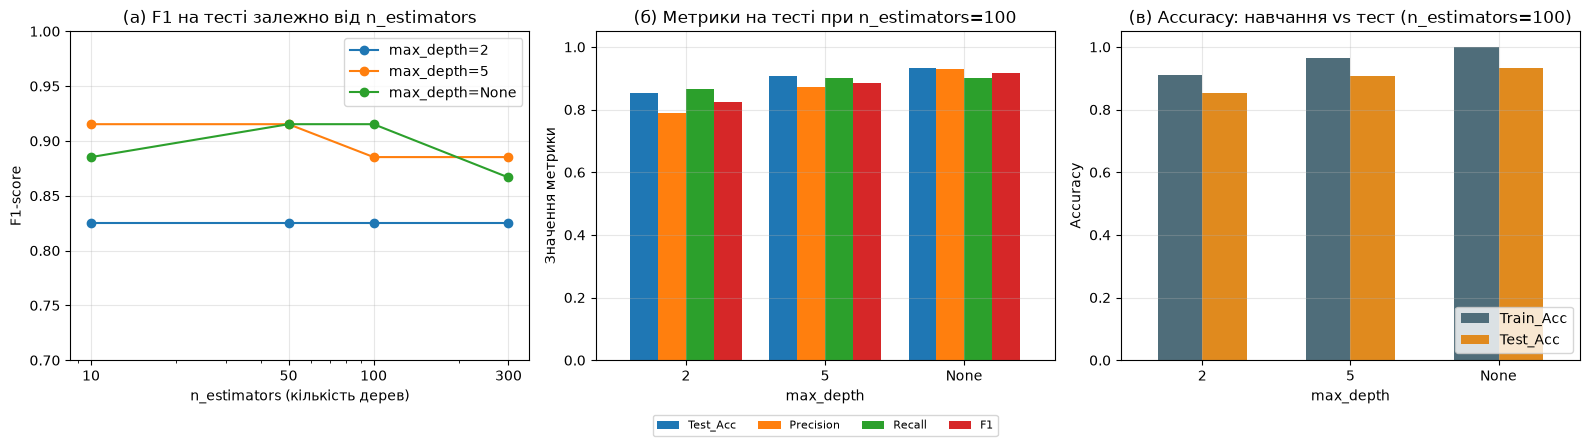

In [25]:
depth_labels = [2, 5, "None"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (а) F1 на тесті залежно від кількості дерев — окрема лінія для кожної глибини
for d in depth_labels:
    sub = grid[grid["max_depth"] == d]
    axes[0].plot(sub["n_estimators"], sub["F1"], marker="o", label=f"max_depth={d}")
axes[0].set_title("(а) F1 на тесті залежно від n_estimators")
axes[0].set_xlabel("n_estimators (кількість дерев)")
axes[0].set_ylabel("F1-score")
axes[0].set_xscale("log"); axes[0].set_xticks([10, 50, 100, 300]); axes[0].set_xticklabels([10, 50, 100, 300])
axes[0].set_ylim(0.7, 1.0)   # масштаб осі обмежено для наочності: різниці невеликі
axes[0].legend()

# (б) порівняння метрик для різної глибини при n_estimators=100
sub = grid[grid["n_estimators"] == 100].set_index("max_depth").loc[depth_labels]
sub[["Test_Acc", "Precision", "Recall", "F1"]].plot(kind="bar", ax=axes[1], rot=0, width=0.8)
axes[1].set_title("(б) Метрики на тесті при n_estimators=100")
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("Значення метрики")
axes[1].set_ylim(0, 1.05); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8)

# (в) навчальна й тестова accuracy — ознака перенавчання
sub[["Train_Acc", "Test_Acc"]].plot(kind="bar", ax=axes[2], rot=0, width=0.6,
                                    color=["#4F6D7A", "#E08A1E"])
axes[2].set_title("(в) Accuracy: навчання vs тест (n_estimators=100)")
axes[2].set_xlabel("max_depth"); axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0, 1.05); axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Додатково: `min_samples_leaf` та `max_features`
Беремо `n_estimators=100`, `max_depth=None` і змінюємо по одному параметру. Оскільки ознак лише дві,
`max_features=2` означає «усі ознаки» (випадковість у виборі ознак вимикається), а `max_features=1` — одна випадкова ознака на вузол.

In [26]:
extra = []
for v in [1, 3, 5, 10, 20]:
    extra.append({"параметр": "min_samples_leaf", "значення": v, **run_config(n_estimators=100, min_samples_leaf=v)})
for v in [1, 2]:
    extra.append({"параметр": "max_features", "значення": v, **run_config(n_estimators=100, max_features=v)})
pd.DataFrame(extra).round(3)

,параметр,значення,Train_Acc,Test_Acc,Precision,Recall,F1,ROC-AUC,CV_F1,Час_навч_с
0,min_samples_leaf,1,1.000,0.933,0.931,0.900,0.915,0.952,0.869,0.096
1,min_samples_leaf,3,0.947,0.933,0.931,0.900,0.915,0.953,0.892,0.087
2,min_samples_leaf,5,0.929,0.893,0.867,0.867,0.867,0.937,0.875,0.092
3,min_samples_leaf,10,0.911,0.853,0.788,0.867,0.825,0.951,0.877,0.087
4,min_samples_leaf,20,0.911,0.853,0.788,0.867,0.825,0.942,0.877,0.086
5,max_features,1,1.000,0.933,0.931,0.900,0.915,0.952,0.869,0.087
6,max_features,2,1.000,0.880,0.862,0.833,0.847,0.933,0.854,0.090


### Вибір налаштувань за крос-валідацією (без тесту) і фінальна оцінка
З 12 конфігурацій беремо ту, що має найвищий `CV_F1` на навчальній вибірці (при рівності — з меншою кількістю дерев).
Лише після цього один раз оцінюємо її на тесті.

In [27]:
best = grid.sort_values(["CV_F1", "n_estimators"], ascending=[False, True]).iloc[0]
best_depth = None if best["max_depth"] == "None" else int(best["max_depth"])
best_n = int(best["n_estimators"])
print(f"Обрано за CV на train: n_estimators={best_n}, max_depth={best_depth}, CV_F1={best['CV_F1']:.3f}")

rf_tuned = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=RANDOM_STATE)
rf_tuned.fit(X_train, y_train)
pd.DataFrame([evaluate(rf_tuned, X_test, y_test)], index=["RandomForest (обрані за CV)"]).round(3)

Обрано за CV на train: n_estimators=100, max_depth=5, CV_F1=0.888


,Accuracy,Precision,Recall,F1,ROC-AUC
RandomForest (обрані за CV),0.907,0.871,0.9,0.885,0.956


In [28]:
# Короткий автоматичний підсумок спостережень (щоб висновки спиралися на фактичні числа)
by_n = grid[grid["max_depth"] == "None"].set_index("n_estimators")["F1"]
by_d = grid[grid["n_estimators"] == 100].set_index("max_depth")
print("F1 на тесті при max_depth=None, залежно від n_estimators:", by_n.round(3).to_dict())
print("Test F1 при n_estimators=100, залежно від max_depth:     ", by_d["F1"].round(3).to_dict())
print("Train_Acc - Test_Acc при n_estimators=100:               ",
      (by_d["Train_Acc"] - by_d["Test_Acc"]).round(3).to_dict())
print("Розмах F1 між усіма 12 конфігураціями: від", grid["F1"].min().round(3), "до", grid["F1"].max().round(3))

F1 на тесті при max_depth=None, залежно від n_estimators: {10: 0.885, 50: 0.915, 100: 0.915, 300: 0.867}
Test F1 при n_estimators=100, залежно від max_depth:      {2: 0.825, 5: 0.885, 'None': 0.915}
Train_Acc - Test_Acc при n_estimators=100:                {2: 0.058, 5: 0.058, 'None': 0.067}
Розмах F1 між усіма 12 конфігураціями: від 0.825 до 0.915


**Що показали фактичні результати** (запуск зі scikit-learn 1.8.0; в інших версіях числа можуть дещо відрізнятися):
- **`max_depth=2`:** усі чотири значення `n_estimators` дають однакові метрики на тесті (accuracy 0,853, F1 0,825) — занадто проста межа обмежує модель незалежно від кількості дерев (недонавчання). ROC-AUC зростає з 0,923 (10 дерев) до 0,946–0,950 (50–300 дерев) і далі майже не змінюється — це типове насичення.
- **Кількість дерев:** для `max_depth=None` F1 на тесті не зростає монотонно (0,885 → 0,915 → 0,915 → 0,867), а для 300 дерев навіть нижчий. Різниця — це 1–2 об'єкти з 75, тобто в межах шуму, а не доказ того, що «300 гірше за 100». Час навчання при цьому зростає приблизно пропорційно кількості дерев (≈0,12 с → ≈0,35 с).
- **Глибина:** при `max_depth=None` точність на навчанні 1,000 (дерева повністю запам'ятовують навчальні дані), на тесті 0,893–0,933. Розрив Train−Test при 100 деревах: 0,058 (depth=2), 0,058 (depth=5), 0,067 (depth=None). Тобто явного сильного перенавчання ми не бачимо: голосування багатьох дерев його стримує, а головна різниця в тому, що глибина 2 дає **нижчу якість** на обох вибірках (недонавчання).
- **Крос-валідація на навчальній вибірці** дає значно менший розкид (`CV_F1` 0,859–0,892), ніж єдиний тест (F1 0,825–0,915). Тому найкращу конфігурацію обрано за CV: `n_estimators=100`, `max_depth=5`. Вона показала на тесті F1 = 0,885, що **нижче**, ніж у моделі за замовчуванням (0,915): це нагадування, що на 75 об'єктах різниця в 2 об'єкти легко змінює порядок конфігурацій.
- **`max_features`:** при `max_features=2` (усі ознаки, випадковий вибір ознак вимкнено) accuracy на тесті 0,880 проти 0,933 при `max_features=1`; CV_F1 теж трохи нижчий (0,854 проти 0,869). Це узгоджується з ідеєю декореляції дерев, але з двома ознаками та малим тестом висновок слабкий.
- **`min_samples_leaf`:** збільшення до 10–20 згладжує межу і знижує якість на тесті (F1 0,825) — знову ознака недонавчання; значення 3 дало найвищий CV_F1 (0,892).

**Як читати ці результати (теорія):**
- *Більше дерев ≠ різко вищий рівень якості.* Усереднення багатьох дерев зменшує **дисперсію** прогнозу, але цей ефект
  швидко насичується: після певної кількості дерев нові дерева майже не змінюють голосування. Від кількості дерев ліс
  зазвичай не перенавчається; додаткові дерева лише збільшують час навчання та розмір моделі.
- *Глибина впливає на баланс «недонавчання — перенавчання».* Дуже малі `max_depth` дають занадто просту межу (високе зміщення),
  необмежена глибина дає складну межу, що може підлаштовуватися під шум (великий розрив між Train_Acc і Test_Acc).
- Якщо фактичні числа вище не збігаються з цими очікуваннями — довіряйте числам, а не теорії: тест малий, тому різниці в 1–3 п.п. можуть бути шумом.

## 7. Візуалізація: границі рішень і важливість ознак
### Графік 4. Границі рішень: одне дерево та Random Forest
Фон показує, який клас передбачає модель у кожній точці площини. Кружечки — навчальні об'єкти, трикутники — тестові.

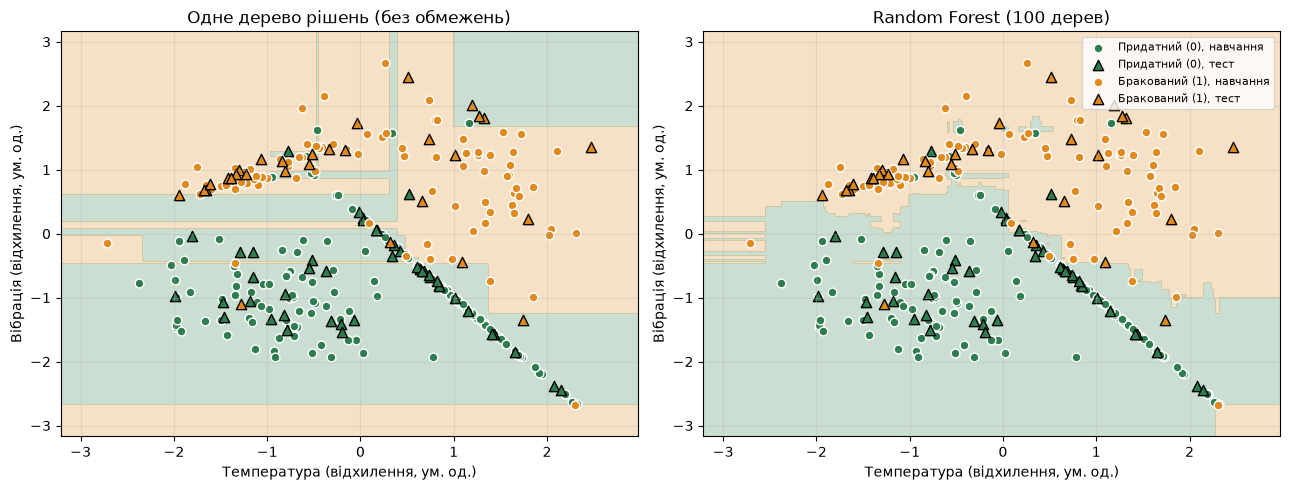

In [29]:
def plot_boundary(ax, model, title):
    x_min, x_max = X["Температура"].min() - 0.5, X["Температура"].max() + 0.5
    y_min, y_max = X["Вібрація"].min() - 0.5, X["Вібрація"].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid_pts = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)
    zz = model.predict(grid_pts).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=[COLORS[0], COLORS[1]], alpha=0.25)
    for cls in (0, 1):
        tr, te = (y_train == cls), (y_test == cls)
        ax.scatter(X_train.loc[tr, "Температура"], X_train.loc[tr, "Вібрація"], c=COLORS[cls],
                   edgecolor="white", s=40, marker="o", label=f"{CLASS_NAMES[cls]}, навчання")
        ax.scatter(X_test.loc[te, "Температура"], X_test.loc[te, "Вібрація"], c=COLORS[cls],
                   edgecolor="black", s=55, marker="^", label=f"{CLASS_NAMES[cls]}, тест")
    ax.set_title(title)
    ax.set_xlabel("Температура (відхилення, ум. од.)")
    ax.set_ylabel("Вібрація (відхилення, ум. од.)")

dt_single = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_boundary(axes[0], dt_single, "Одне дерево рішень (без обмежень)")
plot_boundary(axes[1], rf, "Random Forest (100 дерев)")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Графік 5. Важливість ознак
Показано два способи: `feature_importances_` (за зменшенням неоднорідності Gini, обчислюється на навчальних даних)
та **permutation importance** на тесті (на скільки падає F1 після перемішування ознаки).

**Обмеження `feature_importances_`:** рахується за навчальною вибіркою (може відображати перенавчання); зміщений на користь
неперервних ознак із багатьма можливими порогами; при корельованих ознаках «ділить» важливість між ними;
показує внесок у модель, а не причинно-наслідковий зв'язок. Тому його варто доповнювати permutation importance.
У нас лише дві ознаки, тож графік простий, але принцип той самий.

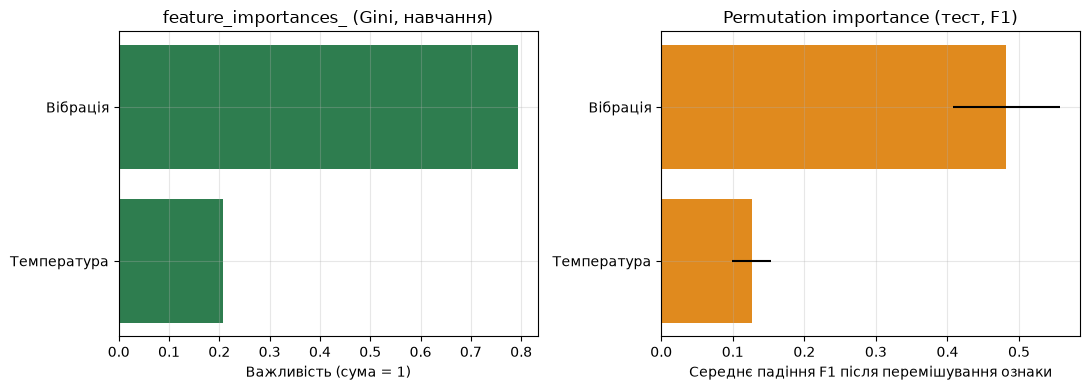

feature_importances_: {'Температура': 0.207, 'Вібрація': 0.793}
permutation (середнє ± std): {'Температура': '0.127±0.027', 'Вібрація': '0.482±0.075'}


In [30]:
imp_gini = pd.Series(rf.feature_importances_, index=feature_names)
perm = permutation_importance(rf, X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(feature_names, imp_gini.values, color="#2E7D4F")
axes[0].set_title("feature_importances_ (Gini, навчання)")
axes[0].set_xlabel("Важливість (сума = 1)")
axes[1].barh(feature_names, perm.importances_mean, xerr=perm.importances_std, color="#E08A1E")
axes[1].set_title("Permutation importance (тест, F1)")
axes[1].set_xlabel("Середнє падіння F1 після перемішування ознаки")
plt.tight_layout()
plt.show()
print("feature_importances_:", imp_gini.round(3).to_dict())
print("permutation (середнє ± std):", {n: f"{m:.3f}±{s:.3f}" for n, m, s in zip(feature_names, perm.importances_mean, perm.importances_std)})

## 8. Порівняння моделей
`DecisionTreeClassifier`, `RandomForestClassifier` і `GradientBoostingClassifier` навчаються на **тих самих** `X_train`/`y_train`
і оцінюються на тому самому `X_test`. **Параметри — за замовчуванням** (RF: `n_estimators=100`), на тесті нічого не підбиралося.

In [31]:
models = {
    "DecisionTree":     DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest":     RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    rows[name] = {**evaluate(model, X_test, y_test), "Час_навч_с": elapsed}
comparison = pd.DataFrame(rows).T
comparison.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Час_навч_с
DecisionTree,0.867,0.917,0.733,0.815,0.844,0.002
RandomForest,0.933,0.931,0.900,0.915,0.952,0.088
GradientBoosting,0.907,0.926,0.833,0.877,0.924,0.059


Через малий тест (75 об'єктів) одна вибірка може дати випадковий результат. Для перевірки стійкості висновків
додатково виконаємо **повторну стратифіковану крос-валідацію** (5 блоків × 3 повтори) на всьому наборі даних.
Це лише оцінка якості, налаштування моделей при цьому не змінюються.

In [32]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X, y, cv=rcv, scoring=["accuracy", "f1"])
    cv_rows[name] = {
        "Accuracy (сер.)": res["test_accuracy"].mean(), "Accuracy (std)": res["test_accuracy"].std(),
        "F1 (сер.)": res["test_f1"].mean(),             "F1 (std)": res["test_f1"].std(),
    }
cv_table = pd.DataFrame(cv_rows).T
cv_table.round(3)

,Accuracy (сер.),Accuracy (std),F1 (сер.),F1 (std)
DecisionTree,0.894,0.032,0.863,0.044
RandomForest,0.926,0.030,0.905,0.038
GradientBoosting,0.914,0.033,0.891,0.043


**Коментар до порівняння моделей** (за результатами цього запуску):
- На єдиному тесті Random Forest має найвищі метрики (accuracy 0,933, F1 0,915, ROC-AUC 0,952), далі Gradient Boosting (F1 0,877) та одне дерево (F1 0,815). Найбільша різниця в **recall** (0,900 проти 0,733 у одного дерева): одне дерево частіше пропускає бракований виріб.
- Повторна крос-валідація (15 розбиттів) підтверджує **порядок** (RF 0,905 → GB 0,891 → DT 0,863 за F1), але різниці між RF і GB (≈0,014) значно менші за стандартне відхилення (≈0,04), тому стверджувати, що RF «краще» за бустинг на цих даних, не можна. Перевага над одним деревом помітніша, але теж скромна.
- Параметри GB та DT не підбиралися; результат градієнтного бустингу з налаштованими параметрами міг би бути іншим. Узагальнювати висновок на інші дані не слід.

## 9. Висновки
1. Random Forest правильно класифікував 93,3 % тестових об'єктів (accuracy 0,933; F1 0,915; ROC-AUC 0,952) на синтетичній задачі з шумом у мітках.
2. Ансамбль дає **гладшу границю рішень**, ніж одне дерево (графік 4) та вищий recall: менше пропущених бракованих виробів.
3. Кількість дерев стабілізує результат, але після 50–100 дерев приріст якості практично зникає; більше дерев = довше навчання без гарантованого виграшу.
4. Занадто мала глибина (`max_depth=2`) призводить до недонавчання; необмежені дерева запам'ятовують навчальні дані (accuracy 1,000), проте ліс на тесті все одно утримує якість — однак не слід вважати, що перенавчання неможливе.
5. Через малий тест (75 об'єктів) і синтетичність даних різниці в 1–3 п.п. слід трактувати обережно; для серйозних висновків потрібні більші/реальні дані й вкладена крос-валідація.
6. `feature_importances_` вказує на «Вібрацію» як головну ознаку (0,793 проти 0,207), permutation importance підтверджує порядок (0,482 проти 0,127), але це лише внесок у модель, а не причинний зв'язок.